# Day 99 – House Price Prediction: Model Evaluation & Comparison

## Objective
The objective of this phase is to evaluate the performance of trained regression models and identify the best-performing model for house price prediction.

## Evaluation Metrics
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R² Score

## Models
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor

## Workflow
- Load and prepare the dataset.
- Recreate the preprocessing workflow.
- Train all three regression models.
- Evaluate their performance using regression metrics.
- Compare model results.
- Visualize model performance.

**Project:** House Price Prediction  
**Day:** 99/100  
**Phase:** Model Evaluation & Comparison

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving train (2).csv to train (2).csv


In [3]:
df = pd.read_csv("train (2).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (1460, 81)


In [4]:
df = df.drop("Id", axis=1)

X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1460, 79)
Target shape: (1460,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1168
Testing samples: 292


In [6]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 36
Categorical features: 43


In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Both preprocessing pipelines created!")

Both preprocessing pipelines created!


In [8]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [9]:
linear_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

linear_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

print("All three models trained successfully!")

All three models trained successfully!


In [10]:
linear_predictions = linear_model.predict(X_test)
tree_predictions = tree_model.predict(X_test)
forest_predictions = forest_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [11]:
linear_mae = mean_absolute_error(y_test, linear_predictions)
tree_mae = mean_absolute_error(y_test, tree_predictions)
forest_mae = mean_absolute_error(y_test, forest_predictions)

print("Linear Regression MAE:", round(linear_mae, 2))
print("Decision Tree MAE:", round(tree_mae, 2))
print("Random Forest MAE:", round(forest_mae, 2))

Linear Regression MAE: 20466.13
Decision Tree MAE: 26452.03
Random Forest MAE: 17394.56


In [12]:
linear_mse = mean_squared_error(y_test, linear_predictions)
tree_mse = mean_squared_error(y_test, tree_predictions)
forest_mse = mean_squared_error(y_test, forest_predictions)

print("Linear Regression MSE:", round(linear_mse, 2))
print("Decision Tree MSE:", round(tree_mse, 2))
print("Random Forest MSE:", round(forest_mse, 2))

Linear Regression MSE: 979376460.09
Decision Tree MSE: 1696723579.97
Random Forest MSE: 806350063.93


In [13]:
linear_rmse = np.sqrt(linear_mse)
tree_rmse = np.sqrt(tree_mse)
forest_rmse = np.sqrt(forest_mse)

print("Linear Regression RMSE:", round(linear_rmse, 2))
print("Decision Tree RMSE:", round(tree_rmse, 2))
print("Random Forest RMSE:", round(forest_rmse, 2))

Linear Regression RMSE: 31294.99
Decision Tree RMSE: 41191.3
Random Forest RMSE: 28396.3


In [14]:
linear_r2 = r2_score(y_test, linear_predictions)
tree_r2 = r2_score(y_test, tree_predictions)
forest_r2 = r2_score(y_test, forest_predictions)

print("Linear Regression R2 Score:", round(linear_r2, 4))
print("Decision Tree R2 Score:", round(tree_r2, 4))
print("Random Forest R2 Score:", round(forest_r2, 4))

Linear Regression R2 Score: 0.8723
Decision Tree R2 Score: 0.7788
Random Forest R2 Score: 0.8949


In [15]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [linear_mae, tree_mae, forest_mae],
    "MSE": [linear_mse, tree_mse, forest_mse],
    "RMSE": [linear_rmse, tree_rmse, forest_rmse],
    "R2 Score": [linear_r2, tree_r2, forest_r2]
})

results.round(2)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,20466.13,9.793765e+08,31294.99,0.87
1,Decision Tree,26452.03,1.696724e+09,41191.30,0.78
2,Random Forest,17394.56,8.063501e+08,28396.30,0.89


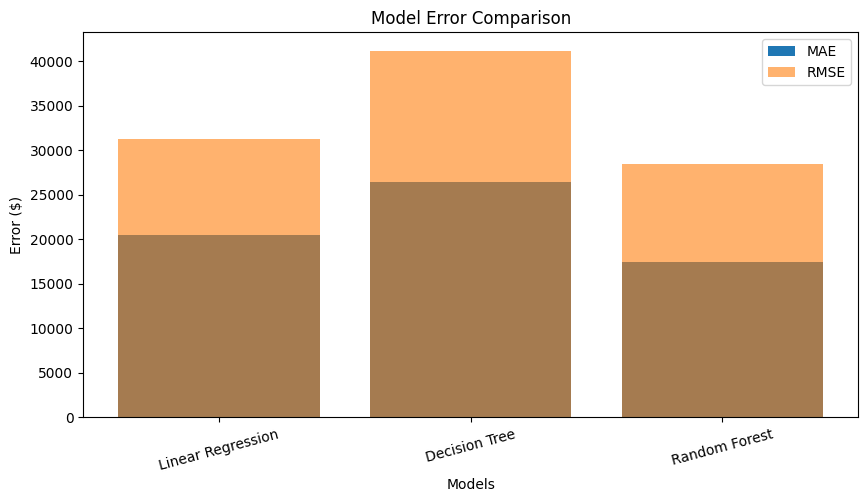

In [16]:
plt.figure(figsize=(10, 5))

plt.bar(results["Model"], results["MAE"], label="MAE")
plt.bar(results["Model"], results["RMSE"], alpha=0.6, label="RMSE")

plt.title("Model Error Comparison")
plt.ylabel("Error ($)")
plt.xlabel("Models")
plt.legend()
plt.xticks(rotation=15)
plt.show()

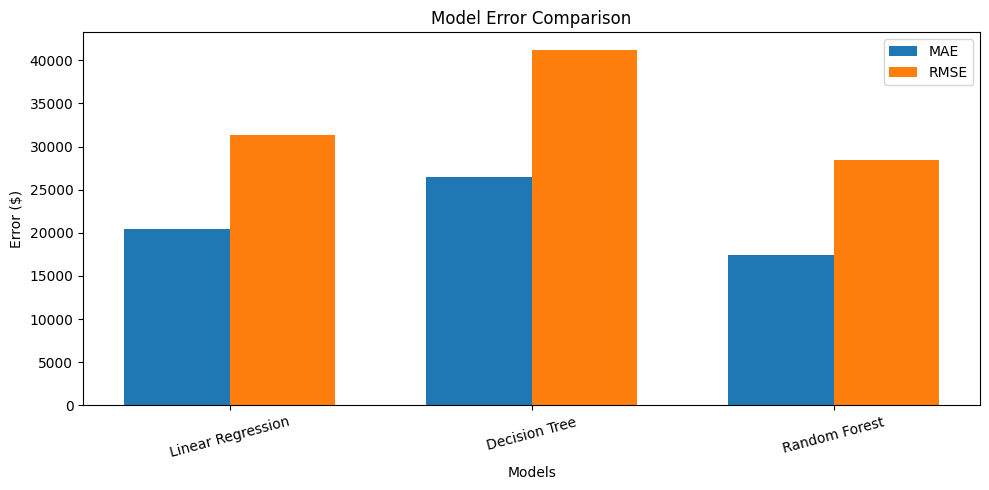

In [17]:
x = np.arange(len(results["Model"]))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, results["MAE"], width, label="MAE")
plt.bar(x + width/2, results["RMSE"], width, label="RMSE")

plt.title("Model Error Comparison")
plt.ylabel("Error ($)")
plt.xlabel("Models")
plt.xticks(x, results["Model"], rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

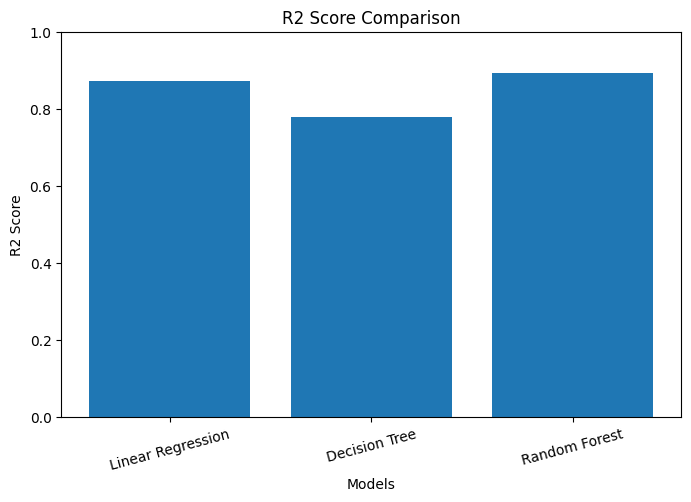

In [18]:
plt.figure(figsize=(8, 5))

plt.bar(results["Model"], results["R2 Score"])

plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xlabel("Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()

## Day 99 Conclusion — Model Evaluation & Comparison

Today, I evaluated three Machine Learning regression models for the House Price Prediction project: Linear Regression, Decision Tree Regressor, and Random Forest Regressor.

I assessed their performance using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² Score. I also created visualizations to compare prediction errors and R² scores across the three models.

Random Forest Regressor performed the best in this experiment, achieving the lowest MAE of 17,394.56, lowest RMSE of 28,396.30, and highest R² score of 0.8949. Linear Regression also performed reasonably well, while Decision Tree showed comparatively higher prediction errors.

Based on these evaluation results, Random Forest Regressor was selected as the best-performing model among the three tested models.

**Day 99/100 Completed.**